# Cloud supersaturation retrievals at EPCAPE: learning Jeramy Dedrick's methods

This notebook explains, step by step, how **Dedrick et al. (2026)** estimate the *effective cloud supersaturation* at EPCAPE. It re-derives the retrievals from the posted data where the inputs exist, and it **recreates their Fig. 10**.

**Sources**
| What | Where |
|---|---|
| Paper | Dedrick, J. L., and coauthors, 2026: Quantitative estimates of upwind and on-site particle scavenging and retrieved cloud supersaturations from urban coastal stratocumulus during EPCAPE. *J. Atmos. Sci.*, **83**, 1061–1082, https://doi.org/10.1175/JAS-D-26-0004.1 (methods: Sec. 2b, 2d; results: Sec. 5; supplement Texts S3, S4, S10, Table S7) |
| Posted data | "Aerosol Quantification Products at Mt. Soledad and Scripps Pier during EPCAPE 2023-24", UC San Diego Library, https://doi.org/10.6075/J0WM1DSC (part of collection https://doi.org/10.6075/J0NG4QT4). A partial local copy is in `data/processed/Aerosol Quantification Products/` |
| Code (MATLAB) | GitHub user **jdedrick95**: `kappakohler` (κ-Köhler theory), `ParcelActivation_ARG2000` (parcel parameterization), `ParcelSupersaturation_MOD1`, `create_PSD`. `Corrected_PierCCN_ARM_EPCAPE` is **empty**. The interpolation code for the CCN-based retrievals is not posted. The CCN-correction code is in the Library item as `EPCAPE_Pier_CCNclosure_and_correction.zip`, which is not in the local copy |

**What this notebook finds** (details in each part)
1. The posted `supersaturation.txt` has its **`skappa` and `sCCN` columns swapped**. The paper's figure is right. Evidence is in Part 2.
2. The **cloud-scene retrieval** (s_Nd, FM-120 at Mt. Soledad) is reproduced to r ≈ 0.95, and the **Hoppel-minimum CCN retrieval** (s_CCN) to r ≈ 0.94–0.97, from the posted inputs.
3. Most EPCAPE cloud-scene retrievals fall **below the CCN counter's lowest setpoint, 0.1 %**. There the answer depends only on the CCN count at 0.1 %, which is the value Sourita's correction changes (Part 4).
4. The κ (s_κ) and parcel (s_ARG00) retrievals need files that are not in the local copy. Both methods are explained and coded here, and they run approximately with typical inputs.
5. The posted parcel code (`ParcelActivation_ARG2000.m`) has an Aitken-mode copy-paste error and what look like unit and radius/diameter inconsistencies (Part 7).

**Layout:** Part 1 physics → Part 2 data → Part 3 CCN spectrum → Part 4 cloud-scene retrieval (s_Nd) → Part 5 Hoppel-minimum + CCN (s_CCN) → Part 6 Hoppel-minimum + κ (s_κ) → Part 7 parcel (s_ARG00) → Part 8 Fig. 10 → Part 9 summary and next steps.

## Part 1. The physics, in plain terms

**Supersaturation.** Air is *saturated* when its water-vapour pressure *e* equals the saturation vapour pressure over a flat water surface, *e*ₛ(T). The **supersaturation** is how far above that it is, in percent:

$$s = \left(\frac{e}{e_s(T)} - 1\right)\times 100\,\%$$

In clouds *s* is tiny, about 0.01–1 %. No instrument measures it directly in a cloud. Fast, accurate temperature and humidity at the needed precision are not available, so it must be *inferred*.

**Why droplets need supersaturation: Köhler theory.** Water condenses on aerosol particles. Two effects compete:
* **curvature (Kelvin effect):** a small, strongly curved droplet evaporates more easily, so it needs a *higher* saturation ratio to stay in equilibrium;
* **dissolved salt (Raoult effect):** dissolved material lowers the vapour pressure, so a *lower* saturation ratio suffices.

**κ-Köhler theory** (Petters & Kreidenweis, 2007, *ACP* 7, 1961) puts all the chemistry into one number, the hygroscopicity **κ**. Roughly κ ≈ 0.1 for organics, 0.6 for ammonium sulfate and 1.1 for sea salt. For a particle of dry diameter *D*_d that has grown to wet diameter *D*, the equilibrium saturation ratio is

$$S(D) = \frac{D^3 - D_d^3}{D^3 - D_d^3\,(1-\kappa)}\;\exp\!\left(\frac{A}{D}\right), \qquad A = \frac{4\,\sigma_w M_w}{R\,T\,\rho_w}\approx 2.1\ \text{nm at } 298\text{ K}$$

*S*(*D*) has a peak, the **critical supersaturation** *s*_c. If the air's supersaturation exceeds *s*_c, the particle grows without limit: it **activates** into a cloud droplet. For κ ≳ 0.2 the peak is approximately (Petters & Kreidenweis 2007, eq. 10)

$$\ln S_c \approx s_c \approx \sqrt{\frac{4A^3}{27\,\kappa\,D_d^3}}$$

So **bigger and more soluble particles activate at lower supersaturation**: *s*_c ∝ *D*_d^(−3/2) κ^(−1/2).

**What sets the cloud's supersaturation.** In a rising air parcel the air cools and *s* rises. Once particles activate, the new droplets soak up vapour, and *s* peaks at *S*_max before falling. Every particle with *s*_c < *S*_max becomes a droplet. Therefore

$$N_d = \text{CCN}(S_{\max})$$

The droplet number equals the number of particles that *can* activate at the cloud's peak supersaturation. Polluted air holds many CCN, and they compete for the vapour, so *S*_max stays low (the "competition" effect). Stronger updrafts cool faster and raise *S*_max.

**The CCN counter.** It draws air through a chamber held at a known supersaturation (a *setpoint*) and counts the particles that grow into droplets. Stepping through setpoints gives the **CCN spectrum**, CCN(*s*). At the Pier the setpoints were 0.1, 0.2, 0.4, 0.6, 0.8 and 1.0 %.

**The Hoppel minimum.** Particles that activate in a cloud gain mass from aqueous chemistry. When the droplets evaporate, they come back out *larger* than before. After a few cloud cycles, the dry size distribution has a gap, the **Hoppel minimum diameter *D*_HM**, between the particles that activated (accumulation mode) and those that did not (Aitken mode). *D*_HM is roughly the critical diameter of the recent clouds. Because it records the *largest* supersaturation those clouds reached, it is biased high.

**The four retrievals in the paper (Fig. 1; Table S7)**
| Method | Idea | Inputs (all hourly) |
|---|---|---|
| **s_κ** (history-based) | *s*_c of a particle of size *D*_HM, from κ-Köhler theory | *D*_HM (Pier size-distribution fits), κ from ACSM composition |
| **s_CCN** (history-based) | the *s* at which CCN(*s*) = number of particles larger than *D*_HM | Pier CCN spectrum, Pier mode fits and *D*_HM |
| **s_Nd** (cloud-scene) | the *s* at which CCN(*s*) = measured droplet number *N*_d | Pier CCN spectrum; *N*_d from FM-120 (Mt. Soledad cloud events) or ARM NDROP (Pier low-cloud periods) |
| **s_ARG00** (parcel) | *S*_max of a rising parcel, from the Abdul-Razzak & Ghan (2000) parameterization | Pier mode fits, κ, sub-cloud updraft w*, cloud-base T and p |

The paper judges the **cloud-scene** method (s_Nd) the most realistic: about 0.1 % at EPCAPE against about 0.3 % for LASIC. The Hoppel-minimum methods record ensemble maxima and come out higher (0.28–0.40 %).

In [1]:
# --- Setup: make the EPCAPE package importable (same pattern as check_seasonal_averages.ipynb) --------------------
# The EPCAPE folder is itself the Python package (config.yaml at its top level), so its PARENT folder goes on sys.path.
import sys
from pathlib import Path


def find_repo_root(start: Path = Path.cwd()) -> Path:
    # Walk up from the notebook's folder to the EPCAPE folder (it holds config.yaml and __init__.py).
    for p in [start, *start.parents]:
        if (p / "config.yaml").is_file() and (p / "__init__.py").is_file():
            return p
    raise FileNotFoundError(f"Could not find the EPCAPE folder above {start}")


REPO = find_repo_root()
if str(REPO.parent) not in sys.path:
    sys.path.insert(0, str(REPO.parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.special import erfc  # complementary error function, for the lognormal "number above D" integral

from EPCAPE.download_data.config import active_machine
from EPCAPE.comparisons.seasonal_averages import sources as SRC  # load_fm120 (Mt. Soledad FM-120, 5-min)
from EPCAPE.plotting import INK, INK_2, INK_3, use_style

use_style()
pd.set_option("display.width", 200, "display.max_columns", 20)
MACHINE = active_machine()
PRODUCTS = MACHINE.processed_dir() / "Aerosol Quantification Products"  # local copy of the Library item
FIG_DIR = Path.cwd() / "figures"  # figures from this notebook
FIG_DIR.mkdir(exist_ok=True)
print(f"EPCAPE folder: {REPO}\nposted products: {PRODUCTS}\nfigures: {FIG_DIR}")

# ---------------------------------------------------------------------------------------------------------------------
# Settings (each choice that changes a number). The values reproduce the posted retrievals (checked in Parts 4-5).
# ---------------------------------------------------------------------------------------------------------------------
S_SET_PCT = np.array([0.1, 0.2, 0.4, 0.6, 0.8, 1.0])  # Pier CCN-200 supersaturation setpoints (%), columns of CCN.txt
S_EXT_LOW_PCT, S_EXT_HIGH_PCT = 0.0, 1.2  # paper Sec. 2d: spectrum extended linearly to (0 %, 0 cm-3) and to 1.2 %
CCN_GAP_FILL_H = 2  # hourly CCN at a setpoint missing -> linear interpolation in time across up to 2 missing hours
FM_CLOUD_LWC_GM3 = 0.01  # FM-120 5-min intervals count as "in cloud" when LWC > 0.01 g m-3 (paper Sec. 2b, Text S7)

EPCAPE folder: /Users/andrewbuggee/Documents/VS_CODE/Python-Research/EPCAPE
posted products: /Users/andrewbuggee/Documents/VS_CODE/Python-Research/EPCAPE/data/processed/Aerosol Quantification Products
figures: /Users/andrewbuggee/Documents/VS_CODE/Python-Research/EPCAPE/comparisons/supersaturation/figures


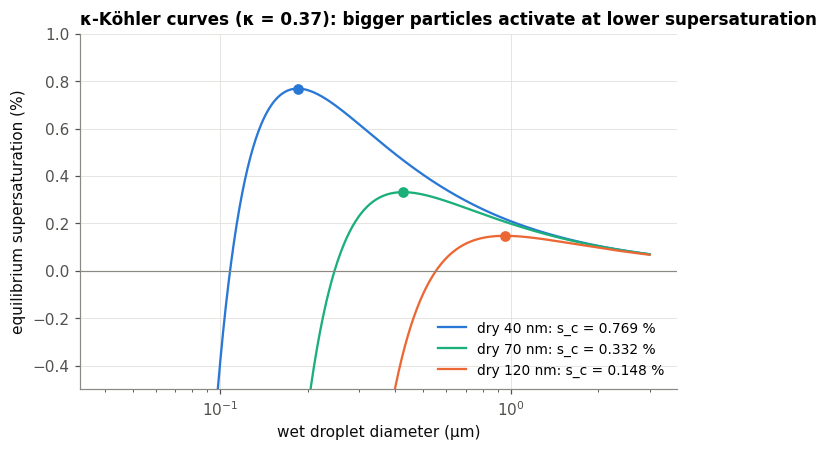

s = 0.1 %  ->  critical dry diameter   156 nm (κ = 0.37)
s = 0.2 %  ->  critical dry diameter    98 nm (κ = 0.37)
s = 0.4 %  ->  critical dry diameter    62 nm (κ = 0.37)
s = 0.6 %  ->  critical dry diameter    47 nm (κ = 0.37)
s = 0.8 %  ->  critical dry diameter    39 nm (κ = 0.37)
s = 1.0 %  ->  critical dry diameter    34 nm (κ = 0.37)


In [2]:
# --- κ-Köhler theory: the building block of every method ---------------------------------------------------------
# Constants as in Jeramy's kappakohler.m (Seinfeld & Pandis 2016): note sigma is in N m-1 (his comment says N/m^2).
SIGMA_W = 0.0728  # surface tension of water, N m-1
M_W = 0.018  # molar mass of water, kg mol-1
R_GAS = 8.314  # universal gas constant, J mol-1 K-1
RHO_W = 1000.0  # density of water, kg m-3
T_KOHLER = 298.15  # temperature for the Köhler terms, K (CCN-counter conditions)
A_KELVIN_M = 4 * SIGMA_W * M_W / (RHO_W * R_GAS * T_KOHLER)  # Kelvin parameter A (m), ~2.1e-9 m = 2.1 nm


def kohler_saturation_ratio(d_wet_m, d_dry_m, kappa):
    # Equilibrium saturation ratio S(D) over a solution droplet (Petters & Kreidenweis 2007, eq. 6):
    #   solute (Raoult) term (D^3 - Dd^3)/(D^3 - Dd^3 (1 - kappa))  <  1  : lowers S
    #   curvature (Kelvin) term exp(A/D)                              >  1  : raises S
    d3, dd3 = d_wet_m**3, d_dry_m**3
    return (d3 - dd3) / (d3 - dd3 * (1 - kappa)) * np.exp(A_KELVIN_M / d_wet_m)


def critical_supersaturation_pct(d_dry_m, kappa):
    # Approximate critical supersaturation (%) for kappa >~ 0.2 (Petters & Kreidenweis 2007, eq. 10):
    #   ln S_c = sqrt(4 A^3 / (27 kappa Dd^3)).
    # Jeramy's kappakohler.m (option 1) returns 100*ln(1 + sqrt(...)); for s_c << 1 both equal 100*sqrt(...) to <0.1 %.
    return 100 * np.log(1 + np.sqrt(4 * A_KELVIN_M**3 / (27 * kappa * np.asarray(d_dry_m, float)**3)))


def critical_diameter_m(s_pct, kappa):
    # Inverse of the above: the smallest dry diameter that activates at supersaturation s (kappakohler.m option 2).
    return (4 * A_KELVIN_M**3 / (27 * kappa * np.log(1 + np.asarray(s_pct, float) / 100) ** 2)) ** (1 / 3)


# Teaching figure: Köhler curves for three dry sizes (kappa = 0.37, the paper's mean Pier kappa, Sec. S10)
kappa_demo = 0.37
fig, ax = plt.subplots(figsize=(7, 4.2))
for d_dry_nm, color in ((40, "#2a78d6"), (70, "#1baf7a"), (120, "#eb6834")):
    d_wet = np.logspace(np.log10(1.02 * d_dry_nm * 1e-9), np.log10(3e-6), 800)  # wet diameters (m), above the dry size
    s_pct = 100 * (kohler_saturation_ratio(d_wet, d_dry_nm * 1e-9, kappa_demo) - 1)
    k = np.argmax(s_pct)  # the peak = critical supersaturation, at the critical wet diameter
    ax.plot(d_wet * 1e6, s_pct, color=color, label=f"dry {d_dry_nm} nm: s_c = {s_pct[k]:.3f} %")
    ax.plot(d_wet[k] * 1e6, s_pct[k], "o", color=color, ms=6)
ax.axhline(0, color=INK_3, lw=0.8)
ax.set_xscale("log"); ax.set_ylim(-0.5, 1.0)
ax.set_xlabel("wet droplet diameter (µm)"); ax.set_ylabel("equilibrium supersaturation (%)")
ax.set_title(f"κ-Köhler curves (κ = {kappa_demo}): bigger particles activate at lower supersaturation", loc="left")
ax.legend(loc="lower right")
plt.show()
for s in S_SET_PCT:
    print(f"s = {s:.1f} %  ->  critical dry diameter {1e9 * critical_diameter_m(s, kappa_demo):5.0f} nm (κ = {kappa_demo})")

## Part 2. The posted data

All files are tab-separated, and their times are **MATLAB datenums** (days since year 0).

| File (local name) | Library name | What |
|---|---|---|
| `bb2743661p_34_1_supersaturation.txt` | `EPCAPE_Supersaturation.txt` | the hourly retrieved supersaturations (%) for **Mt. Soledad cloud events** and **Pier low-cloud periods** |
| `bb2743661p_35_1_CCN.txt` | `epcccn2colaavgM1_DedrickCorrected.txt` | Pier CCN (cm⁻³) at the 6 setpoints, 30-min, **already multiplied by 1.57** for the inlet leak (Text S4) |
| `bb2743661p_32_1_PSD_fits.txt` | `EPCAPE_PSD_fits.txt` | 5-min lognormal fits of the merged size distributions (Aitken, accumulation and coarse: N in cm⁻³, D_g in µm, σ_g), D_HM (µm), k-means cluster (1 broad accumulation, 2 bimodal, 3 broad Aitken, 4 noisy) |
| `bb2743661p_30_1_lowCloudPeriods.txt` | `EPCAPE_LowCloudPeriods.txt` | hourly flag for low-cloud periods: single-layer cloud, base and top < 3 km, coupled (\|base − LCL\| < 150 m) |
| FM-120 daily files | (Dalhousie; `data/processed/FM120`) | Mt. Soledad droplet number N_d, 5-min |

**The posted supersaturation file has its `skappa` and `sCCN` columns swapped.** The next cell shows the evidence and corrects the labels.

In [3]:
def from_datenum(x):
    # MATLAB datenum (days since 0000-01-00) -> pandas Timestamp (UTC). 719529 = datenum(1970-01-01).
    return pd.to_datetime(np.asarray(x, float) - 719529, unit="D").round("s")


def read_posted(name):
    df = pd.read_csv(PRODUCTS / name, sep="\t")
    df.index = from_datenum(df.pop("time"))
    df.index.name = "time"
    return df


SS_POSTED = read_posted("bb2743661p_34_1_supersaturation.txt")  # hourly, %, labels as posted
CCN_30 = read_posted("bb2743661p_35_1_CCN.txt")  # 30-min, cm-3, corrected by 1.57
PSD = read_posted("bb2743661p_32_1_PSD_fits.txt")  # 5-min mode fits; diameters in µm
LOW_CLOUD = read_posted("bb2743661p_30_1_lowCloudPeriods.txt")["LowCloudPeriod"].astype(bool)  # hourly flag
CCN_ONLINE = pd.Timestamp("2023-05-23")  # Pier CCN-200 online from 23 May 2023 (paper Table 1, footnote a)
print(f"supersaturation: {SS_POSTED.index[0]} .. {SS_POSTED.index[-1]} ({len(SS_POSTED)} h);  low-cloud hours: {LOW_CLOUD.sum()}")
print(f"CCN: first data {CCN_30.dropna(how='all').index[0]}, last {CCN_30.dropna(how='all').index[-1]}")

# --- Evidence that 'skappa' and 'sCCN' are swapped in the posted file -----------------------------------------------
# 1. A CCN-based retrieval cannot exist before the Pier CCN counter was online.
# 2. The figure's panel labels (Fig. 10a s_CCN, 10b s_kappa) match the posted columns the other way round.
FIG10_LABELS = {  # mean ± std printed in the paper's Fig. 10 (light = low-cloud periods, dark = Soledad cloud events)
    ("CCN", "LowCloudPeriod"): "0.31±0.21", ("CCN", "SoledadCloudEvent"): "0.45±0.29",
    ("kappa", "LowCloudPeriod"): "0.33±0.19", ("kappa", "SoledadCloudEvent"): "0.32±0.17",
    ("Nd", "LowCloudPeriod"): "0.13±0.14", ("Nd", "SoledadCloudEvent"): "0.07±0.05",
    ("ARG00", "LowCloudPeriod"): "0.1±0.06", ("ARG00", "SoledadCloudEvent"): "0.03±0.02"}
rows = []
for col in SS_POSTED.columns:
    v = SS_POSTED[col].dropna()
    rows.append({"posted column": col, "hours": len(v), "first hour": v.index.min(),
                 "hours before CCN online": int((v.index < CCN_ONLINE).sum()), "posted mean±std": f"{v.mean():.2f}±{v.std():.2f}"})
display(pd.DataFrame(rows).set_index("posted column"))
print("Fig. 10 labels:", FIG10_LABELS)

# Correct the labels: what the file calls skappa is s_CCN and vice versa (Part 5 confirms it against an independent
# re-derivation of s_CCN, r = 0.94-0.97)
SS = SS_POSTED.rename(columns=lambda c: c.replace("skappa_", "TMP_").replace("sCCN_", "skappa_").replace("TMP_", "sCCN_"))
assert (SS["sCCN_LowCloudPeriod"].dropna().index >= CCN_ONLINE).all(), "s_CCN before the CCN counter was online"
print("\nLabels corrected: the column posted as 'skappa_*' is now 'sCCN_*' and vice versa.")

supersaturation: 2023-02-15 00:00:00 .. 2024-02-15 00:00:00 (8761 h);  low-cloud hours: 334
CCN: first data 2023-05-23 15:00:00, last 2024-02-13 23:30:00


,hours,first hour,hours before CCN online,posted mean±std
posted column,,,,
skappa_SoledadCloudEvent,128,2023-06-03 15:00:00,0,0.42±0.27
sCCN_SoledadCloudEvent,238,2023-03-12 21:00:00,61,0.31±0.18
sNd_SoledadCloudEvent,177,2023-06-03 15:00:00,0,0.06±0.05
sARG00_SoledadCloudEvent,168,2023-03-12 21:00:00,50,0.03±0.02
skappa_LowCloudPeriod,194,2023-05-23 22:00:00,0,0.31±0.21
sCCN_LowCloudPeriod,316,2023-03-12 21:00:00,66,0.33±0.19
sNd_LowCloudPeriod,255,2023-05-23 22:00:00,0,0.13±0.14
sARG00_LowCloudPeriod,246,2023-03-16 17:00:00,57,0.10±0.06


Fig. 10 labels: {('CCN', 'LowCloudPeriod'): '0.31±0.21', ('CCN', 'SoledadCloudEvent'): '0.45±0.29', ('kappa', 'LowCloudPeriod'): '0.33±0.19', ('kappa', 'SoledadCloudEvent'): '0.32±0.17', ('Nd', 'LowCloudPeriod'): '0.13±0.14', ('Nd', 'SoledadCloudEvent'): '0.07±0.05', ('ARG00', 'LowCloudPeriod'): '0.1±0.06', ('ARG00', 'SoledadCloudEvent'): '0.03±0.02'}

Labels corrected: the column posted as 'skappa_*' is now 'sCCN_*' and vice versa.


## Part 3. The Pier CCN spectrum, and how one hourly spectrum is built

The CCN-200 **steps through its setpoints**, about 10 min each, so any 30-min average holds only 1–3 of the 6 setpoints (first table below). An hourly spectrum therefore needs a rule for the missing setpoints. The paper does not state its rule. The one used here reproduces the posted retrievals best (Part 4):
1. average each setpoint over the hour, [t, t + 1 h);
2. where a setpoint has no value in that hour, interpolate it linearly in time from the neighbouring hours, across at most `CCN_GAP_FILL_H` = 2 missing hours.

30-min rows by number of setpoints with data: {0: 2542, 1: 932, 2: 3804, 3: 5587}


,0.1%,0.2%,0.4%,0.6%,0.8%,1.0%
time,,,,,,
2023-06-01 00:00:00,153.0,237.0,NaN,NaN,NaN,NaN
2023-06-01 00:30:00,NaN,NaN,304.0,393.0,469.0,NaN
2023-06-01 01:00:00,NaN,NaN,NaN,NaN,NaN,496.0
2023-06-01 01:30:00,145.0,217.0,258.0,NaN,NaN,NaN
2023-06-01 02:00:00,NaN,NaN,NaN,307.0,362.0,394.0
2023-06-01 02:30:00,149.0,240.0,NaN,NaN,NaN,NaN
2023-06-01 03:00:00,NaN,NaN,272.0,338.0,395.0,NaN


complete hourly spectra: 5,184


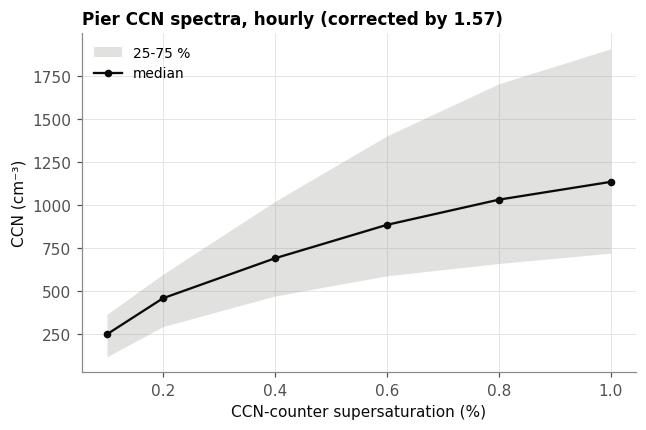

In [4]:
c30 = CCN_30.loc[CCN_ONLINE:]
print("30-min rows by number of setpoints with data:", c30.notna().sum(axis=1).value_counts().sort_index().to_dict())
display(c30.loc["2023-06-01 00:00":"2023-06-01 03:00"].round(0))  # the setpoints rotate through the rows

# hourly spectrum: hourly mean per setpoint, then short gaps filled in time (see the markdown above)
CCN_H = c30.resample("1h").mean().interpolate(method="time", limit=CCN_GAP_FILL_H, limit_area="inside")
CCN_H = CCN_H[CCN_H.notna().all(axis=1)]  # keep complete spectra only
print(f"complete hourly spectra: {len(CCN_H):,}")

# the campaign's spectra: median and interquartile range at each setpoint
fig, ax = plt.subplots(figsize=(6.5, 4))
q = CCN_H.quantile([0.25, 0.5, 0.75])
ax.fill_between(S_SET_PCT, q.loc[0.25], q.loc[0.75], color=INK_3, alpha=0.25, lw=0, label="25-75 %")
ax.plot(S_SET_PCT, q.loc[0.5], "o-", color=INK, label="median")
ax.set_xlabel("CCN-counter supersaturation (%)"); ax.set_ylabel("CCN (cm⁻³)")
ax.set_title("Pier CCN spectra, hourly (corrected by 1.57)", loc="left"); ax.legend(loc="upper left")
plt.show()

## Part 4. The cloud-scene retrieval, s_Nd: where does the CCN spectrum reach the droplet number?

Because *N*_d = CCN(*S*_max) (Part 1), the cloud's effective supersaturation is the *s* at which the hourly CCN spectrum equals the hourly droplet number. Following the paper (Sec. 2d):
* connect the six setpoints with **straight lines** (linear interpolation);
* below 0.1 %, draw a straight line to **0 cm⁻³ at 0 %**;
* above 1.0 %, extend the last segment linearly to 1.2 %;
* drop any answer above 1.2 % or below 0.

*N*_d at Mt. Soledad comes from the FM-120: the mean of its 5-min values with LWC > 0.01 g m⁻³ in each hour. Cloud events are the hours where the posted file has a value. The Pier low-cloud periods use the ARM NDROP retrieval of *N*_d, which is not downloaded here, so their posted values are used as they are.

**Why the 0.1 % point matters so much.** Below 0.1 %, the spectrum is the straight line from (0, 0) to (0.1 %, CCN₀.₁), so

$$s_{N_d} = 0.1\,\% \times \frac{N_d}{\text{CCN}(0.1\,\%)}$$

Any change to CCN(0.1 %), such as Sourita's correction, rescales every retrieval in that range by the inverse factor.

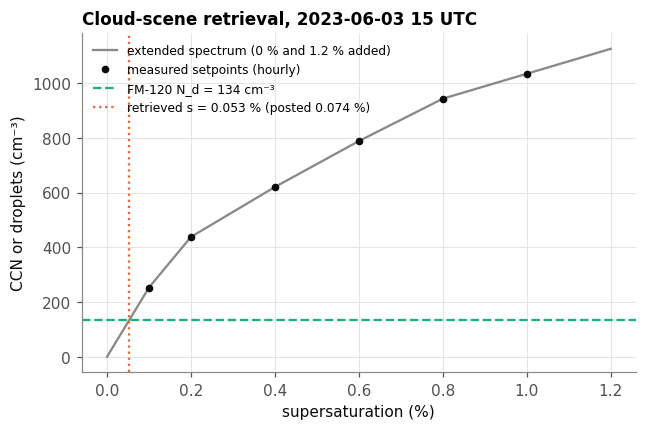

s_Nd,FM re-derived for 177 of 177 posted hours: r = 0.947, median difference -0.0000 %, within ±0.005 %: 77%


In [5]:
S_EXT = np.r_[S_EXT_LOW_PCT, S_SET_PCT, S_EXT_HIGH_PCT]  # 0, 0.1, ..., 1.0, 1.2 %


def extend_spectrum(ccn_6):
    # The 8-point spectrum of the paper: (0 %, 0 cm-3), the 6 setpoints, and 1.2 % from the slope of the last segment.
    c = np.asarray(ccn_6, float)
    slope = (c[-1] - c[-2]) / (S_SET_PCT[-1] - S_SET_PCT[-2])  # cm-3 per % between 0.8 and 1.0 %
    return np.r_[0.0, c, c[-1] + slope * (S_EXT_HIGH_PCT - S_SET_PCT[-1])]


def retrieve_supersaturation_pct(n_target_cm3, ccn_6):
    # The supersaturation (%) where the piecewise-linear CCN spectrum first reaches n_target (cm-3).
    # Walks the 7 straight segments from 0 % upward; returns NaN if the spectrum never reaches n_target (> 1.2 %).
    if not np.isfinite(n_target_cm3) or not np.all(np.isfinite(ccn_6)):
        return np.nan
    c = extend_spectrum(ccn_6)
    for k in range(len(S_EXT) - 1):
        c0, c1 = c[k], c[k + 1]
        if min(c0, c1) <= n_target_cm3 <= max(c0, c1):  # n_target lies on this segment
            if c1 == c0:
                return S_EXT[k]
            return S_EXT[k] + (n_target_cm3 - c0) * (S_EXT[k + 1] - S_EXT[k]) / (c1 - c0)
    return np.nan


# --- one worked example: the first Mt. Soledad cloud-event hour ---------------------------------------------------
FM = SRC.load_fm120()  # 5-min FM-120 (Mt. Soledad): nd_cm3, lwc_gm3, ...
ND_FM_H = FM["nd_cm3"].where(FM["lwc_gm3"] > FM_CLOUD_LWC_GM3).resample("1h").mean()  # in-cloud hourly mean N_d
t0 = SS["sNd_SoledadCloudEvent"].dropna().index[0]
spec0, nd0 = CCN_H.loc[t0].values, ND_FM_H[t0]
s0 = retrieve_supersaturation_pct(nd0, spec0)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(S_EXT, extend_spectrum(spec0), "-", color=INK_3, label="extended spectrum (0 % and 1.2 % added)")
ax.plot(S_SET_PCT, spec0, "o", color=INK, label="measured setpoints (hourly)")
ax.axhline(nd0, color="#1baf7a", ls="--", label=f"FM-120 N_d = {nd0:.0f} cm⁻³")
ax.axvline(s0, color="#eb6834", ls=":", label=f"retrieved s = {s0:.3f} % (posted {SS.loc[t0, 'sNd_SoledadCloudEvent']:.3f} %)")
ax.set_xlabel("supersaturation (%)"); ax.set_ylabel("CCN or droplets (cm⁻³)")
ax.set_title(f"Cloud-scene retrieval, {t0:%Y-%m-%d %H} UTC", loc="left"); ax.legend(loc="upper left", fontsize=8)
plt.show()

# --- every Mt. Soledad cloud-event hour, against the posted values --------------------------------------------------
posted_nd = SS["sNd_SoledadCloudEvent"].dropna()
OURS_SND_FM = pd.Series([retrieve_supersaturation_pct(ND_FM_H.get(t, np.nan), CCN_H.loc[t].values) if t in CCN_H.index
                         else np.nan for t in posted_nd.index], index=posted_nd.index)
ok = OURS_SND_FM.notna()
diff = (OURS_SND_FM - posted_nd)[ok]
print(f"s_Nd,FM re-derived for {ok.sum()} of {len(posted_nd)} posted hours: r = {np.corrcoef(OURS_SND_FM[ok], posted_nd[ok])[0, 1]:.3f}, "
      f"median difference {diff.median():+.4f} %, within ±0.005 %: {(diff.abs() < 0.005).mean():.0%}")

In [6]:
# --- How many retrievals sit below 0.1 % (on the extrapolated line), and how a change in CCN(0.1 %) moves them --------
for col, name in (("sNd_SoledadCloudEvent", "Mt. Soledad cloud events (FM-120)"),
                  ("sNd_LowCloudPeriod", "Pier low-cloud periods (NDROP)")):
    v = SS[col].dropna()
    print(f"{name}: {len(v)} h; below 0.1 %: {(v < 0.1).mean():.0%}; between 0.1 and 0.2 %: {((v >= 0.1) & (v < 0.2)).mean():.0%}")


def snd_with_scaled_ccn01(nd_h, factor):
    # Re-retrieve s_Nd with the CCN count at the 0.1 % setpoint multiplied by `factor` (others unchanged).
    out = {}
    for t in nd_h.index:
        if t in CCN_H.index:
            spec = CCN_H.loc[t].values.copy()
            spec[0] *= factor
            out[t] = retrieve_supersaturation_pct(nd_h[t], spec)
    return pd.Series(out)


# Low-cloud hours: N_d (NDROP) is not downloaded, so use the N_d IMPLIED by each posted value and our spectrum,
# N_d = CCN(s_posted), then re-retrieve with a changed CCN(0.1 %). (Exact where our spectrum equals Jeramy's.)
nd_implied_low = pd.Series({t: np.interp(s, S_EXT, extend_spectrum(CCN_H.loc[t].values))
                            for t, s in SS["sNd_LowCloudPeriod"].dropna().items() if t in CCN_H.index})
nd_fm = ND_FM_H.reindex(posted_nd.index).dropna()
rows = {}
for factor in (0.6, 0.8, 1.0, 1.25, 1.6):
    rows[f"CCN(0.1 %) × {factor}"] = {
        "Soledad s_Nd,FM mean (%)": snd_with_scaled_ccn01(nd_fm, factor).mean(),
        "low-cloud s_Nd,VAP mean (%)": snd_with_scaled_ccn01(nd_implied_low, factor).mean()}
display(Markdown("**Mean cloud-scene supersaturation if the CCN count at the 0.1 % setpoint were scaled** "
                 "(1.0 = as posted; Sourita's correction would set this factor)"))
display(pd.DataFrame(rows).T.round(3))

Mt. Soledad cloud events (FM-120): 177 h; below 0.1 %: 83%; between 0.1 and 0.2 %: 15%
Pier low-cloud periods (NDROP): 255 h; below 0.1 %: 57%; between 0.1 and 0.2 %: 29%


**Mean cloud-scene supersaturation if the CCN count at the 0.1 % setpoint were scaled** (1.0 = as posted; Sourita's correction would set this factor)

,"Soledad s_Nd,FM mean (%)","low-cloud s_Nd,VAP mean (%)"
CCN(0.1 %) × 0.6,0.088,0.154
CCN(0.1 %) × 0.8,0.073,0.141
CCN(0.1 %) × 1.0,0.061,0.128
CCN(0.1 %) × 1.25,0.049,0.114
CCN(0.1 %) × 1.6,0.037,0.093


## Part 5. The Hoppel-minimum CCN retrieval, s_CCN

Same lookup as Part 4, but the target is the **number of particles larger than the Hoppel minimum**, *N*(*D* > *D*_HM). Those are the particles that activated in the recent clouds. For each lognormal mode *i* (number *N*ᵢ, median diameter *D*_g,i, geometric standard deviation σ_g,i), the number above a diameter *D* is

$$N_i(D' > D) = \frac{N_i}{2}\,\operatorname{erfc}\!\left(\frac{\ln(D/D_{g,i})}{\sqrt{2}\,\ln\sigma_{g,i}}\right)$$

The Pier mode fits and *D*_HM are averaged over each hour, and the three modes are summed.

In [7]:
def number_above_cm3(row, site="Pier"):
    # N(D > D_HM) (cm-3) from the three fitted lognormal modes of one (hourly-mean) row of PSD_fits.
    d_hm = row[f"{site}_DHM"]  # µm
    if not np.isfinite(d_hm):
        return np.nan
    total = 0.0
    for mode in ("ait", "acc", "coarse"):
        n, dg, sg = row[f"{site}_{mode}_N"], row[f"{site}_{mode}_diam"], row[f"{site}_{mode}_gsd"]
        if np.isfinite(n) and np.isfinite(dg) and np.isfinite(sg):
            total += 0.5 * n * erfc(np.log(d_hm / dg) / (np.sqrt(2) * np.log(sg)))
    return total


PSD_H = PSD.resample("1h").mean(numeric_only=True)  # hourly-mean fits and D_HM (the "Pier_PSDkmeans" mean is not used)
N_ABOVE_H = PSD_H.apply(number_above_cm3, axis=1)
for col in ("sCCN_LowCloudPeriod", "sCCN_SoledadCloudEvent"):  # corrected labels (Part 2)
    posted = SS[col].dropna()
    ours = pd.Series([retrieve_supersaturation_pct(N_ABOVE_H.get(t, np.nan), CCN_H.loc[t].values) if t in CCN_H.index
                      else np.nan for t in posted.index], index=posted.index)
    ok = ours.notna(); d = (ours - posted)[ok]
    print(f"{col}: re-derived {ok.sum()} of {len(posted)} h, r = {np.corrcoef(ours[ok], posted[ok])[0, 1]:.3f}, "
          f"median difference {d.median():+.4f} %, within ±0.01 %: {(d.abs() < 0.01).mean():.0%}")

sCCN_LowCloudPeriod: re-derived 192 of 194 h, r = 0.943, median difference +0.0012 %, within ±0.01 %: 64%
sCCN_SoledadCloudEvent: re-derived 127 of 128 h, r = 0.970, median difference +0.0010 %, within ±0.01 %: 48%


## Part 6. The Hoppel-minimum κ retrieval, s_κ

The critical supersaturation of a particle exactly at the Hoppel minimum: *s*_κ = *s*_c(*D*_HM, κ), from the Part 1 formula, with κ from the Pier ACSM composition (the Library file `kcalc.nc`, mixing rule κ = Σ εᵢ κᵢ). **`kcalc.nc` is not in the local copy.** This cell uses a constant κ = 0.37, the paper's campaign mean at the Pier (Text S10). With the hourly κ the agreement would be closer. *s*_κ ∝ κ^(−1/2), so a 20 % error in κ moves *s*_κ by about 10 %.

In [8]:
KAPPA_PIER = 0.37  # paper Text S10: submicron kappa at Scripps Pier = 0.37 ± 0.14 (stand-in for kcalc.nc)
s_kappa_ours = pd.Series(critical_supersaturation_pct(PSD_H["Pier_DHM"] * 1e-6, KAPPA_PIER),  # D_HM in µm -> m
                         index=PSD_H.index)
for col in ("skappa_LowCloudPeriod", "skappa_SoledadCloudEvent"):
    posted = SS[col].dropna()
    o = s_kappa_ours.reindex(posted.index); ok = o.notna()
    print(f"{col}: {ok.sum()} h, r = {np.corrcoef(o[ok], posted[ok])[0, 1]:.3f}, median ours/posted = {np.median(o[ok] / posted[ok]):.2f} "
          f"(constant κ = {KAPPA_PIER}; the posted values use the hourly ACSM κ)")

skappa_LowCloudPeriod: 316 h, r = 0.867, median ours/posted = 1.07 (constant κ = 0.37; the posted values use the hourly ACSM κ)
skappa_SoledadCloudEvent: 238 h, r = 0.922, median ours/posted = 1.07 (constant κ = 0.37; the posted values use the hourly ACSM κ)


## Part 7. The parcel retrieval, s_ARG00 (Abdul-Razzak & Ghan 2000)

A rising parcel cools at a rate set by the updraft *w*. Its supersaturation peaks when droplet growth (vapour loss) balances cooling (vapour excess). **Abdul-Razzak et al. (1998, *JGR* 103, 6123)** and **Abdul-Razzak & Ghan (2000, *JGR* 105, 6837)** fit that balance into one formula for *S*_max, given the aerosol modes (*N*ᵢ, *D*_g,i, σ_g,i, κᵢ), *w* and cloud-base *T* and *p*:

$$S_{\max} = \left[\sum_i \frac{1}{S_{m,i}^2}\left( f_i \left(\frac{\zeta}{\eta_i}\right)^{3/2} + g_i \left(\frac{S_{m,i}^2}{\eta_i + 3\zeta}\right)^{3/4}\right)\right]^{-1/2}$$

Here *S*_m,i is the critical supersaturation of the mode's median particle, *f*ᵢ and *g*ᵢ depend on the mode width, and *η*ᵢ ∝ (α*w*/G)^{3/2} / *N*ᵢ is the updraft "supply" per particle. More particles give a smaller *η* and a lower *S*_max (competition). A faster *w* gives a higher *S*_max.

The paper uses the Pier mode fits, κ = 0.37 for both submicron modes, κ = 0.87 for the coarse mode, the Doppler-lidar sub-cloud velocity *w*\* (`EPCAPE_SubCloudVelocity.txt`), and cloud-base *T* and *p* from the ARM INTERPSONDE VAP. **These inputs are not local, so the posted s_ARG00 cannot be re-derived here.** The cell implements the textbook formula, ports Jeramy's posted MATLAB function line by line, and compares the two for typical EPCAPE aerosol.

**Issues in the posted `ParcelActivation_ARG2000.m`** (jdedrick95, dated 14 Jul 2025). The posted code may not be the exact version behind the paper.
* *Certain:* the Aitken mode takes the **accumulation-mode diameter** (`d_aero_mode2 = mode2_param(2)` inside the Aitken block).
* *Likely:* *S*_m and ζ use the diameter-form Kelvin parameter (4σ) with the mode **radius**. ARG2000 pairs the radius-form A (2σ) with the radius, so *S*_m comes out √8 too large and ζ 2× too large.
* *Likely:* α and γ mix **molar** latent heat and heat capacity (J mol⁻¹, J mol⁻¹ K⁻¹) into formulas written per kg. The second term of γ comes out at about 1 % of its correct size.
* *Likely:* ARG2000 eq. 6 takes the square root of the **sum** over modes, but the code sums the per-mode square roots.

With typical inputs these partly cancel: the posted code gives a ~10–25 % lower *S*_max than the textbook formula (table below). My confidence in the "likely" items is moderate. They should be checked against the ARG98/ARG2000 papers and raised with Jeramy.

In [9]:
G_ACC = 9.81  # m s-2
M_A = 0.02897  # molar mass of dry air, kg mol-1
L_V = 2.5e6  # latent heat of vaporization, J kg-1
CP_A = 1005.7  # specific heat of air at constant pressure, J kg-1 K-1
D_V = 2.55e-5  # diffusivity of water vapour in air, m2 s-1
K_A = 2.40e-2  # thermal conductivity of air, J m-1 s-1 K-1
SIGMA_SA = 0.076  # surface tension of the solution, N m-1 (Ghan et al. 2011 value used in the posted code)


def smax_arg2000_pct(modes, w_ms, t_k, p_pa):
    # Textbook ARG2000 (eqs. 6-11 of Abdul-Razzak & Ghan 2000 with alpha, gamma, G of Abdul-Razzak et al. 1998).
    # modes: list of (N m-3, D_g m, sigma_g, kappa). Returns S_max in %.
    es = 611.094 * np.exp(17.625 * (t_k - 273.15) / (t_k - 273.15 + 243.04))  # Magnus formula, Pa
    alpha = G_ACC * M_W * L_V / (CP_A * R_GAS * t_k**2) - G_ACC * M_A / (R_GAS * t_k)  # m-1: cooling drives S up
    gamma = R_GAS * t_k / (es * M_W) + M_W * L_V**2 / (CP_A * p_pa * M_A * t_k)  # m3 kg-1: condensation drives S down
    G = 1 / (RHO_W * R_GAS * t_k / (es * D_V * M_W) + L_V * RHO_W / (K_A * t_k) * (L_V * M_W / (R_GAS * t_k) - 1))  # m2 s-1
    A = 2 * M_W * SIGMA_SA / (R_GAS * t_k * RHO_W)  # Kelvin parameter, RADIUS form (m)
    zeta = (2 / 3) * A * np.sqrt(alpha * w_ms / G)
    total = 0.0
    for n, dg, sg, kap in modes:
        sm = 2 / np.sqrt(kap) * (A / (3 * dg / 2)) ** 1.5  # critical supersaturation of the mode's median radius
        eta = (alpha * w_ms / G) ** 1.5 / (2 * np.pi * RHO_W * gamma * n)
        f = 0.5 * np.exp(2.5 * np.log(sg) ** 2)
        g = 1 + 0.25 * np.log(sg)
        total += (f * (zeta / eta) ** 1.5 + g * (sm**2 / (eta + 3 * zeta)) ** 0.75) / sm**2
    return 100 / np.sqrt(total)


def smax_posted_matlab_pct(modes, w_ms, t_k, p_pa):
    # Line-by-line port of ParcelActivation_ARG2000.m as posted (including the issues listed above).
    lv, cp, Ma, Mw, R = 4.5e4, 1005.7 * 28.97e-3, 28.97e-3, 18.02e-3, 8.3144621  # lv J mol-1; cp J mol-1 K-1
    es = 6.1094 * np.exp(17.625 * (t_k - 273.15) / ((t_k - 273.15) + 243.04)) * 100
    G = RHO_W * R * t_k / (Mw * D_V * es) + RHO_W * lv / (Mw * K_A * t_k) * (lv / (R * t_k) - 1)
    A = 4 * SIGMA_SA * Mw / (RHO_W * R * t_k)  # diameter-form Kelvin parameter...
    (n1, d1, s1, k1), (n2, d2, s2, k2), (n3, _d3, s3, k3) = modes
    d3 = d2  # ...and the Aitken diameter copied from mode 2 (as posted)
    sm = [np.sqrt(4 * A**3 / (27 * k * (d / 2) ** 3)) for k, d in ((k1, d1), (k2, d2), (k3, d3))]  # ...with radius
    alpha = G_ACC * Mw * lv / (cp * R * t_k**2) - G_ACC * Ma / (R * t_k)
    gamma = R * t_k / (es * Mw) + Mw * lv**2 / (cp * p_pa * Ma * t_k)
    zeta = (2 / 3) * np.sqrt(alpha * w_ms * G) * A
    total = 0.0
    for (n, s), smi in zip(((n1, s1), (n2, s2), (n3, s3)), sm):
        eta = (alpha * w_ms * G) ** 1.5 / (2 * np.pi * RHO_W * gamma * n)
        f, g = 0.5 * np.exp(2.5 * np.log(s) ** 2), 1 + 0.25 * np.log(s)
        total += ((f * (zeta / eta) ** 1.5 + g * (smi**2 / (eta + 3 * zeta)) ** 0.75) / smi**2) ** 0.5  # note: sum of roots
    return 100 / total


# Typical EPCAPE Pier aerosol: the paper's Table 2, bimodal cluster (coarse, accumulation, Aitken); SI units
MODES_BIMODAL = [(27e6, 0.40e-6, 2.00, 0.87), (638e6, 0.15e-6, 1.72, 0.37), (371e6, 0.043e-6, 1.53, 0.37)]
T_BASE_K, P_BASE_PA = 285.0, 95000.0  # a typical coastal cloud base (illustration only)
rows = {f"w = {w} m/s": {"textbook ARG2000 (%)": smax_arg2000_pct(MODES_BIMODAL, w, T_BASE_K, P_BASE_PA),
                         "posted MATLAB (%)": smax_posted_matlab_pct(MODES_BIMODAL, w, T_BASE_K, P_BASE_PA)}
        for w in (0.05, 0.1, 0.2, 0.5, 1.0)}
tbl = pd.DataFrame(rows).T
tbl["posted / textbook"] = tbl["posted MATLAB (%)"] / tbl["textbook ARG2000 (%)"]
display(Markdown("**S_max for typical EPCAPE Pier aerosol (bimodal cluster, Table 2), T = 285 K, p = 950 hPa**"))
display(tbl.round(3))
print("Posted s_ARG00 (hours): low-cloud", SS["sARG00_LowCloudPeriod"].count(), "Soledad", SS["sARG00_SoledadCloudEvent"].count(),
      "- the paper's sub-cloud w* median is < 0.2 m/s (Sec. 5a)")

**S_max for typical EPCAPE Pier aerosol (bimodal cluster, Table 2), T = 285 K, p = 950 hPa**

,textbook ARG2000 (%),posted MATLAB (%),posted / textbook
w = 0.05 m/s,0.038,0.036,0.954
w = 0.1 m/s,0.057,0.051,0.892
w = 0.2 m/s,0.085,0.071,0.836
w = 0.5 m/s,0.140,0.109,0.779
w = 1.0 m/s,0.204,0.153,0.750


Posted s_ARG00 (hours): low-cloud 246 Soledad 168 - the paper's sub-cloud w* median is < 0.2 m/s (Sec. 5a)


## Part 8. Recreating Fig. 10

Fig. 10 of the paper shows histograms (a–d) and box plots (e) of the 1-h retrievals: **light grey = Pier low-cloud periods, dark grey = Mt. Soledad cloud events**. The dashed red lines mark the CCN counter's lowest and highest setpoints (0.1 and 1.0 %). This recreation uses the **posted** hourly values, with the column labels corrected (Part 2).

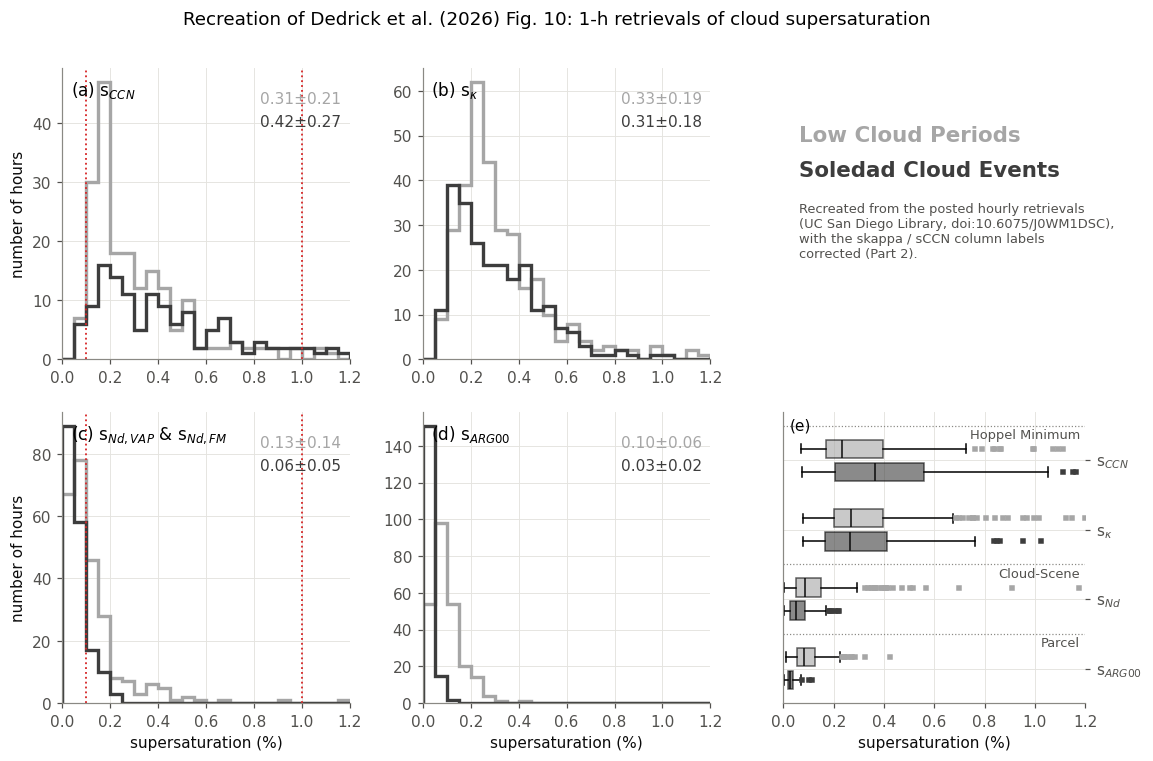

In [10]:
LIGHT, DARK = "#a6a6a6", "#3d3d3d"  # the paper's light and dark grey
PERIODS = (("LowCloudPeriod", LIGHT, "Low Cloud Periods"), ("SoledadCloudEvent", DARK, "Soledad Cloud Events"))
PANELS = (("sCCN", "(a) s$_{CCN}$", True), ("skappa", r"(b) s$_\kappa$", False),
          ("sNd", "(c) s$_{Nd,VAP}$ & s$_{Nd,FM}$", True), ("sARG00", "(d) s$_{ARG00}$", False))
# 0.05 %-wide bins: they reproduce the paper's light-grey peak heights in (a)-(c) (47, 62, 78 h vs ~47, 62, 80 h read off
# the figure). The paper's dark-grey peaks in (c)-(d) suggest MATLAB's automatic, per-series bin widths, not reproduced here.
bins = np.arange(0, 1.2 + 1e-9, 0.05)

fig = plt.figure(figsize=(12, 7.5))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 1.05], wspace=0.25, hspace=0.18)
for k, (method, title, ccn_based) in enumerate(PANELS):
    ax = fig.add_subplot(gs[k // 2, k % 2])
    for period, color, _ in PERIODS:
        v = SS[f"{method}_{period}"].dropna().clip(upper=1.2)
        ax.hist(v, bins=bins, histtype="step", color=color, lw=2.2)
    if ccn_based:  # the CCN counter's setpoint range
        for x in (S_SET_PCT[0], S_SET_PCT[-1]):
            ax.axvline(x, color="#d62728", ls=":", lw=1.2)
    ax.text(0.03, 0.96, title, transform=ax.transAxes, va="top", fontsize=11)
    for j, (p, color, _) in enumerate(PERIODS):
        v = SS[f"{method}_{p}"]
        ax.text(0.97, 0.88 - 0.08 * j, f"{v.mean():.2f}±{v.std():.2f}", transform=ax.transAxes, ha="right",
                color=color, fontsize=10)
    ax.set_xlim(0, 1.2)
    if k % 2 == 0:
        ax.set_ylabel("number of hours")
    if k // 2 == 1:
        ax.set_xlabel("supersaturation (%)")

# (e) box plots, grouped as in the paper
axe = fig.add_subplot(gs[1, 2])
order = [("sCCN", "s$_{CCN}$"), ("skappa", r"s$_\kappa$"), ("sNd", "s$_{Nd}$"), ("sARG00", "s$_{ARG00}$")]
pos, data, colors = [], [], []
for i, (method, _) in enumerate(order):
    for j, (period, color, _) in enumerate(PERIODS):
        pos.append(len(order) * 3 - 3 * i - j)  # top to bottom, light above dark
        data.append(SS[f"{method}_{period}"].dropna().values); colors.append(color)
bp = axe.boxplot(data, positions=pos, vert=False, widths=0.8, patch_artist=True, flierprops=dict(marker="s", ms=2.5))
for patch, flier, c in zip(bp["boxes"], bp["fliers"], colors):
    patch.set_facecolor(c); patch.set_alpha(0.6); flier.set_markerfacecolor(c); flier.set_markeredgecolor(c)
for med in bp["medians"]:
    med.set_color(INK)
axe.set_yticks([len(order) * 3 - 3 * i - 0.5 for i in range(len(order))], [lab for _, lab in order])
axe.yaxis.tick_right()
# group separators (boxes sit at y = 12, 11 | 9, 8 for the Hoppel-minimum methods; 6, 5 cloud-scene; 3, 2 parcel)
for y, lab in ((13.0, "Hoppel Minimum"), (7.0, "Cloud-Scene"), (4.0, "Parcel")):
    axe.axhline(y, color=INK_3, ls=":", lw=0.8)
    axe.text(1.18, y - 0.1, lab, ha="right", va="top", fontsize=8.5, color=INK_2)
axe.set_ylim(1.0, 13.6)
axe.set_xlim(0, 1.2); axe.set_xlabel("supersaturation (%)"); axe.text(0.02, 0.98, "(e)", transform=axe.transAxes, va="top")
# legend text, as in the paper
axl = fig.add_subplot(gs[0, 2]); axl.axis("off")
for j, (_, color, label) in enumerate(PERIODS):
    axl.text(0.05, 0.75 - 0.12 * j, label, color=color, fontsize=14, fontweight="bold", transform=axl.transAxes)
axl.text(0.05, 0.35, "Recreated from the posted hourly retrievals\n(UC San Diego Library, doi:10.6075/J0WM1DSC),\n"
         "with the skappa / sCCN column labels\ncorrected (Part 2).", fontsize=8.5, color=INK_2, transform=axl.transAxes)
fig.suptitle("Recreation of Dedrick et al. (2026) Fig. 10: 1-h retrievals of cloud supersaturation", y=0.95, fontsize=12)
fig.savefig(FIG_DIR / "dedrick2026_fig10_recreated.png", dpi=200, bbox_inches="tight")
plt.show()

In [11]:
# --- The numbers behind the figure, next to the paper's labels and this notebook's re-derivations ------------------
rows = []
for method, name in (("sCCN", "s_CCN"), ("skappa", "s_κ"), ("sNd", "s_Nd"), ("sARG00", "s_ARG00")):
    for period, _, label in PERIODS:
        v = SS[f"{method}_{period}"].dropna()
        key = {"sCCN": "CCN", "skappa": "kappa", "sNd": "Nd", "sARG00": "ARG00"}[method]
        rows.append({"method": name, "period": label, "hours": len(v), "posted mean ± std (%)": f"{v.mean():.2f} ± {v.std():.2f}",
                     "median (%)": round(v.median(), 3), "Fig. 10 label": FIG10_LABELS[(key, period)],
                     "below 0.1 % (%)": round(100 * (v < 0.1).mean())})
display(pd.DataFrame(rows).set_index(["method", "period"]))

hours posted mean ± std (%)  median (%) Fig. 10 label  below 0.1 % (%)
method  period                                                                                      
s_CCN   Low Cloud Periods       194           0.31 ± 0.21       0.233     0.31±0.21                4
        Soledad Cloud Events    128           0.42 ± 0.27       0.362     0.45±0.29                5
s_κ     Low Cloud Periods       316           0.33 ± 0.19       0.270     0.33±0.19                3
        Soledad Cloud Events    238           0.31 ± 0.18       0.265     0.32±0.17                5
s_Nd    Low Cloud Periods       255           0.13 ± 0.14       0.087     0.13±0.14               57
        Soledad Cloud Events    177           0.06 ± 0.05       0.049     0.07±0.05               83
s_ARG00 Low Cloud Periods       246           0.10 ± 0.06       0.084      0.1±0.06               62
        Soledad Cloud Events    168           0.03 ± 0.02       0.025     0.03±0.02               99

## Part 9. Summary and next steps

**What the methods say about EPCAPE clouds.** Coastal clouds at EPCAPE form in particle-rich air with weak updrafts (median w\* < 0.2 m s⁻¹), so the many CCN compete for vapour and the clouds' effective supersaturation is low: about 0.05–0.1 % from the cloud-scene and parcel methods. The Hoppel-minimum methods give about 0.3 %, because *D*_HM records the largest supersaturation of recent cloud cycles, not the typical one.

**Why Sourita's correction matters (Part 4).** Most cloud-scene retrievals lie *below* the lowest CCN setpoint (0.1 %), on the straight line from (0, 0) to (0.1 %, CCN₀.₁). There the retrieved supersaturation is inversely proportional to the CCN count at 0.1 %. The table in Part 4 shows the mean for a range of correction factors. s_κ and s_ARG00 do not use the CCN counter, so they would not change.

**Files to get from the Library item (doi:10.6075/J0WM1DSC) to complete the re-derivation**
* `kcalc.nc`: hourly Pier κ, for s_κ (Part 6) and s_ARG00;
* `EPCAPE_SubCloudVelocity.txt`: w\*, for s_ARG00 (Part 7);
* `SMPS_APS_merged.nc`: the measured merged size distributions, to check the mode-fit integral (Part 5);
* `EPCAPE_Pier_CCNclosure_and_correction.zip`: Jeramy's MATLAB code for the 1.57 correction;
* ARM: the NDROP VAP (*N*_d for the low-cloud periods) and INTERPSONDE (cloud-base *T*, *p*).

**Questions for Jeramy and Veronica**
1. The posted `EPCAPE_Supersaturation.txt` has `skappa` and `sCCN` swapped (Part 2). Can the Library file be corrected?
2. How were missing CCN setpoints filled within an hour (Part 3)? The 2-h time interpolation here reproduces 72–77 % of hours to within 0.005 %.
3. Was the posted `ParcelActivation_ARG2000.m` the version used for the paper (Part 7)?
4. Sourita's correction: is it a new factor for the 0.1 % CCN count that replaces or adds to 1.57, or a correction of the setpoint itself?